# 01 · Preparación de los datos

**Responsable:** Ignacio González

Este notebook toma el CSV original de Seattle, revisa su calidad, aplica las decisiones de limpieza y genera `data/processed/datos_limpios.csv`, que usan los notebooks de los dos modelos.

**Fuente:** *SPU Solid Waste Tons and Trips Data*, City of Seattle, identificador `293h-ej5h`, https://cos-data.seattle.gov/d/293h-ej5h

In [1]:
# Paso 1 · Importar librerías

# pandas: maneja tablas de datos como un Excel pero con código
import pandas as pd

# matplotlib: hace gráficos
import matplotlib.pyplot as plt

# Calendario de feriados de EE. UU., que trae pandas incluido (Se usa debido al dataset de ese país)
from pandas.tseries.holiday import USFederalHolidayCalendar

In [2]:
# Paso 2 · Cargar y mirar los datos
# Qué hacemos: leer el CSV y mirar su forma antes de tocar nada.
# Por qué: no podés limpiar algo que no conocés. Este paso responde: cuántos datos hay, qué columnas, de qué tipo.

# Leemos el CSV. La ruta empieza con ".." porque el notebook está dentro de "notebooks/"
# y tiene que subir una carpeta para llegar a "data/".
# decimal="," le indica que en este archivo los decimales vienen con coma
# (formato argentino), no con punto como en el original
df = pd.read_csv("../data/raw/seattle_tons_trips.csv", decimal=",")

# shape devuelve (cantidad de filas, cantidad de columnas)
print(df.shape)

# dtypes muestra el tipo de dato de cada columna
print(df.dtypes)

# head() muestra las primeras 5 filas (es la última línea, así que se muestra sola)
df.head()

(36215, 8)
YEAR                  int64
MONTH                 int64
Date                    str
Transfer Station        str
COMMODITY               str
TONS                float64
TRIPS                 int64
SECTOR                  str
dtype: object


,YEAR,MONTH,Date,Transfer Station,COMMODITY,TONS,TRIPS,SECTOR
0,2009,5,05/04/2009,North Transfer Station,Garbage,131.514968,23,Residential
1,2009,5,05/04/2009,South Transfer Station,Recycling,315.151139,70,Residential
2,2009,5,05/05/2009,South Transfer Station,Garbage,69.426921,15,Residential
3,2009,5,05/05/2009,South Transfer Station,Recycling,317.744168,71,Residential
4,2009,5,05/05/2009,South Transfer Station,Organics,198.330000,33,Residential


**Decimales:** el archivo trae los decimales con coma, por lo que se indica `decimal=","` para que pandas lea las toneladas como número (`float64`) y no como texto.

In [3]:
# Paso 3 · Renombrar columnas y convertir la fecha
# Qué hacemos: pasar los nombres al castellano, convertir la fecha a tipo fecha
# y traducir los valores de estación y tipo de residuo.
# Por qué: nombres en castellano hacen el código más fácil de leer;
# como texto, la fecha no se puede ordenar, filtrar por año ni saber qué día de la semana fue.

# rename recibe un diccionario {nombre_viejo: nombre_nuevo}
df = df.rename(columns={
    "Date": "fecha",
    "Transfer Station": "estacion",
    "COMMODITY": "tipo",
    "TONS": "toneladas",
    "TRIPS": "viajes",
    "SECTOR": "sector",
})

# Convertimos el texto a fecha. %m = mes, %d = día, %Y = año con 4 dígitos.
# El format evita que pandas confunda el 5 de abril con el 4 de mayo,
# porque el dataset usa el formato estadounidense mes/día/año
df["fecha"] = pd.to_datetime(df["fecha"], format="%m/%d/%Y")

# map reemplaza cada valor según el diccionario
df["estacion"] = df["estacion"].map({
    "North Transfer Station": "Norte",
    "South Transfer Station": "Sur",
})
df["tipo"] = df["tipo"].map({
    "Garbage": "Basura",
    "Recycling": "Reciclables",
    "Organics": "Organicos",
})

# Verificamos: ninguna estación o tipo tiene que haber quedado vacío.
# Si map encuentra un valor que no está en el diccionario, lo deja vacío (NaN)
print("Vacíos en estación:", df["estacion"].isna().sum())
print("Vacíos en tipo:", df["tipo"].isna().sum())

df.dtypes

Vacíos en estación: 0
Vacíos en tipo: 0


YEAR                  int64
MONTH                 int64
fecha        datetime64[us]
estacion                str
tipo                    str
toneladas           float64
viajes                int64
sector                  str
dtype: object

Se renombraron las columnas al castellano y se convirtió la fecha a tipo fecha, indicando el formato mes/día/año del dataset original. Ninguna estación ni tipo de residuo quedó sin traducir.

In [4]:
# Paso 4 · Valores faltantes y duplicados exactos

# Qué hacemos: contar celdas vacías y filas idénticas.

# Por qué: la consigna pide revisarlo y explicar las decisiones. Un vacío puede hacer fallar el modelo, y una fila copiada cuenta dos veces el mismo dato.

# isna() marca True donde hay un vacío; sum() cuenta cuántos True hay por columna
print("Faltantes por columna:")
print(df.isna().sum())

# duplicated() marca True en las filas idénticas a una anterior, en TODAS las columnas
print("\nFilas duplicadas exactas:", df.duplicated().sum())

Faltantes por columna:
YEAR         0
MONTH        0
fecha        0
estacion     0
tipo         0
toneladas    0
viajes       0
sector       0
dtype: int64

Filas duplicadas exactas: 0


No se encontraron valores faltantes ni filas duplicadas exactas, por lo que no fue necesario eliminar ni completar datos en este paso.

In [5]:
# Paso 5 · Columnas que no aportan

# Qué hacemos: contar cuántos valores distintos tiene cada columna y eliminar las que no sirven.

# Por qué: una columna con un único valor es igual para todos los casos, así que no ayuda a distinguir nada. Y las columnas que repiten información de otra solo agregan riesgo de contradicciones.

# nunique() cuenta los valores distintos de cada columna
print(df.nunique())

# Eliminamos:
# - sector: tiene un solo valor ("Residential"), no distingue ningún caso
# - YEAR y MONTH: son información que ya está en la fecha;
#   en el Paso 11 las volvemos a crear a partir de ella, así hay una sola fuente
df = df.drop(columns=["sector", "YEAR", "MONTH"])

print("\nColumnas que quedan:", df.columns.tolist())

YEAR            18
MONTH           12
fecha         6386
estacion         2
tipo             3
toneladas    34540
viajes         126
sector           1
dtype: int64

Columnas que quedan: ['fecha', 'estacion', 'tipo', 'toneladas', 'viajes']


Se eliminó `sector` por tener un único valor (todos los registros son residenciales). Se eliminaron `YEAR` y `MONTH` porque se obtienen de la fecha; mantener una sola fuente evita inconsistencias.

In [6]:
# Paso 6 · Filas repetidas para la misma fecha, estación y tipo

# Qué hacemos: buscar si una misma combinación de fecha, estación y tipo aparece más de una vez.

# Por qué: para el modelo, cada fila tiene que representar una sola cosa: “lo que recibió una estación en un día para un tipo de residuo”. Si hay varias filas para lo mismo, hay que decidir qué hacer antes de seguir.

# Las columnas que deberían identificar a cada fila de forma única
clave = ["fecha", "estacion", "tipo"]

# duplicated con subset compara SOLO esas columnas (no toneladas ni viajes)
print("Combinaciones repetidas:", df.duplicated(subset=clave).sum())

# keep=False marca TODAS las filas del grupo repetido, no solo las copias;
# las ordenamos por la clave para verlas juntas
df[df.duplicated(subset=clave, keep=False)].sort_values(clave).head(6)

Combinaciones repetidas: 8533


,fecha,estacion,tipo,toneladas,viajes
4730,2009-03-30,Sur,Basura,66.599767,12
22746,2009-03-30,Sur,Basura,124.145728,31
13852,2009-03-30,Sur,Organicos,59.050000,11
18284,2009-03-30,Sur,Organicos,114.610000,22
4731,2009-03-31,Sur,Basura,1.400000,1
22747,2009-03-31,Sur,Basura,235.940487,43


Se encontraron **8.533 combinaciones** de fecha, estación y tipo con más de una fila y valores distintos. El dataset no identifica a qué corresponde cada fila; por la descripción oficial (*contracted haulers*), probablemente sean distintos contratistas.

**Decisión:** se **sumaron** para obtener el total diario recibido, que es la cantidad que se busca predecir. Borrarlas perdería toneladas reales y promediarlas no representaría ninguna cantidad concreta.

In [7]:
# groupby agrupa las filas que tienen la misma clave;
# [["toneladas", "viajes"]].sum() suma esas dos columnas dentro de cada grupo;
# as_index=False deja fecha, estación y tipo como columnas normales (no como índice)
df = df.groupby(clave, as_index=False)[["toneladas", "viajes"]].sum()

print("Filas después de sumar:", len(df))

# Verificación: ahora no tiene que quedar ninguna combinación repetida
print("Combinaciones repetidas ahora:", df.duplicated(subset=clave).sum())

Filas después de sumar: 27682
Combinaciones repetidas ahora: 0


In [8]:
# Paso 7 · Valores imposibles

# Qué hacemos: buscar toneladas en cero o negativas, y eliminarlas.

# Por qué: un camión no puede descargar cero ni menos de cero toneladas. Son ajustes contables o errores de carga.

# La condición devuelve True/False por fila; sum() cuenta los True
print("Toneladas en cero o negativas:", (df["toneladas"] <= 0).sum())

# Las miramos antes de borrarlas: ¿de qué años son?
df[df["toneladas"] <= 0].head(10)

Toneladas en cero o negativas: 37


,fecha,estacion,tipo,toneladas,viajes
26,2009-04-04,Sur,Organicos,0.00,1
29,2009-04-05,Sur,Reciclables,0.00,1
88,2009-04-18,Sur,Organicos,0.00,1
92,2009-04-19,Sur,Organicos,0.00,1
123,2009-04-26,Norte,Basura,-5.95,4
154,2009-05-03,Norte,Basura,0.00,3
252,2009-05-24,Norte,Basura,0.00,2
317,2009-06-07,Norte,Basura,0.00,5
349,2009-06-14,Norte,Basura,0.00,4
381,2009-06-21,Norte,Basura,0.00,3


In [9]:
# Filtramos: nos quedamos solo con las filas donde la condición es True
df = df[df["toneladas"] > 0]
print("Filas:", len(df))

Filas: 27645


Se eliminaron **37 días** con toneladas en cero o negativas, que no son cargas posibles. Casi todos son fines de semana de 2009, con viajes registrados pero sin peso, lo que indica registros incompletos o corregidos. Se aplicó después de sumar porque muchas filas negativas del archivo original eran correcciones que se compensan con las demás cargas del mismo día.

In [10]:
# Paso 8 · Combinaciones casi vacías

# Qué hacemos: contar cuántos días tiene cada combinación de estación y tipo de residuo.

# Por qué: un modelo aprende de ejemplos. Si una combinación tiene muy pocos, no puede aprender nada sobre ella, y sus predicciones para ese caso serían adivinanzas.

# size() cuenta cuántas filas hay en cada grupo de estación y tipo
df.groupby(["estacion", "tipo"]).size()

estacion  tipo       
Norte     Basura         4878
          Organicos      3957
          Reciclables       2
Sur       Basura         6378
          Organicos      6148
          Reciclables    6282
dtype: int64

In [11]:
# El símbolo ~ significa "no": nos quedamos con todo lo que NO sea Norte + Reciclables.
# & significa "y": las dos condiciones se tienen que cumplir a la vez.
# Cada condición va entre paréntesis porque & se evalúa antes que ==
df = df[~((df["estacion"] == "Norte") & (df["tipo"] == "Reciclables"))]
print("Filas:", len(df))

Filas: 27643


Se excluyeron los reciclables de la estación Norte: solo tienen 2 días registrados en todo el período, insuficientes para que el modelo aprenda algo de esa combinación. En la práctica, los reciclables residenciales se reciben en la estación Sur.

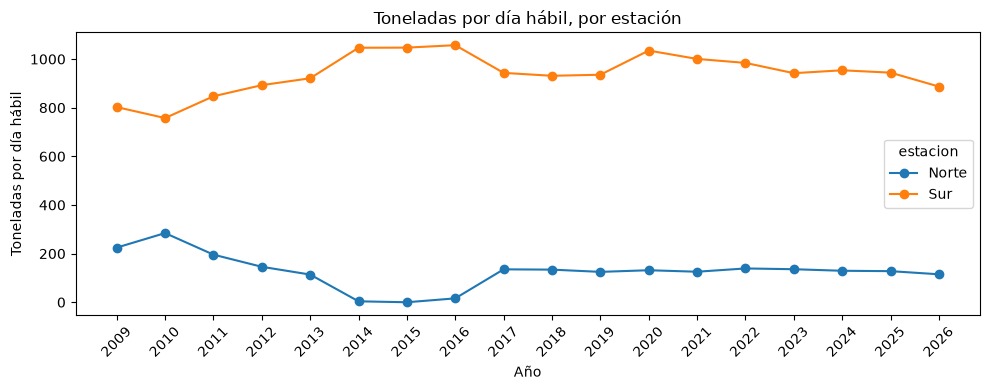

In [12]:
# Paso 9 · Graficar en el tiempo

# Qué hacemos: ver cuántas toneladas recibió cada estación por día hábil, año por año.

# Por qué: un modelo aprende de lo que pasó, y asume que el futuro se va a comportar igual. 
# Si en algún período el sistema funcionó distinto (una estación cerrada, rutas reasignadas), 
# el modelo aprendería reglas que hoy no se cumplen. Las tablas no muestran esos cambios; un gráfico sí.

# Solo días hábiles, para que los fines de semana (casi sin actividad)
# no distorsionen la comparación entre años
habiles = df[df["fecha"].dt.dayofweek < 5]

# Año de cada fila, para agrupar
anio = habiles["fecha"].dt.year

# Total de toneladas por año y estación.
# unstack pasa las estaciones a columnas (una línea por estación en el gráfico);
# fill_value=0 pone 0 si una estación no tuvo ningún registro ese año
total = habiles.groupby([anio, "estacion"])["toneladas"].sum().unstack(fill_value=0)

# Cantidad de días hábiles con datos en cada año (de cualquier estación)
dias = habiles.groupby(anio)["fecha"].nunique()

# Toneladas por día hábil = total del año / días del año.
# axis=0 divide cada fila (cada año) por su cantidad de días
por_dia = total.div(dias, axis=0)

ax = por_dia.plot(marker="o", figsize=(10, 4))
ax.set_xticks(por_dia.index)          # un tick por año, sin decimales
ax.tick_params(axis="x", rotation=45)  # años inclinados para que no se pisen
ax.set_title("Toneladas por día hábil, por estación")
ax.set_xlabel("Año")
ax.set_ylabel("Toneladas por día hábil")
plt.tight_layout()                     # ajusta márgenes para que no se corten las etiquetas
plt.show()

In [13]:
# Cuántos días hábiles tuvo registros cada estación, por año.
# nunique cuenta fechas distintas (cada fecha tiene una fila por tipo de residuo)
habiles.groupby([anio, "estacion"])["fecha"].nunique().unstack(fill_value=0)

estacion,Norte,Sur
fecha,,
2009,199,199
2010,259,261
2011,259,260
2012,258,261
2013,257,261
2014,13,261
2015,0,261
2016,50,261
2017,255,260


**Observaciones del gráfico**

1. La estación Norte no operó entre 2014 y 2016. La tabla lo dice con números: 13 días en 2014, 0 en 2015 y 50 en 2016, contra unos 260 de un año normal. En el gráfico, su línea cae a cero en esos años.

2. La Sur absorbió ese volumen. En esos mismos años la Sur sube a unas 1.050 toneladas por día. Si sumás las dos estaciones, el total de la ciudad casi no cambia: 2013 da 113 + 921 ≈ 1.034, y 2015 da 0 + 1.047 ≈ 1.047. La basura no desapareció: se recibió en otra estación.

3. Antes de 2014 el reparto también estaba cambiando. Entre 2010 y 2013 la Norte baja año a año (de 280 a 113) mientras la Sur sube. El sistema estaba reorganizando qué recibía cada estación.

4. Desde 2017 todo es estable. La Norte se mantiene cerca de 130 toneladas por día y la Sur entre 930 y 1.030, con unos 260 días por año las dos.

5. El aumento de 2020 en la estación Sur coincide con la pandemia, cuando aumentó el tiempo en los hogares y, con él, la basura residencial. El dataset no registra la causa, por lo que se trata de una interpretación probable.

In [14]:
# Nos quedamos con el período en que las dos estaciones operan de forma estable.
# Se puede comparar una columna de fechas con un texto en formato año-mes-día
df = df[df["fecha"] >= "2017-01-01"]
print("Filas:", len(df))

Filas: 16507


**Decisión:** La estación Norte no registró actividad en 2015 y operó solo 13 días en 2014 y 50 en 2016; en esos años la estación Sur absorbió su volumen, de modo que el total de la ciudad se mantuvo estable. Entre 2010 y 2013 el reparto entre estaciones también cambió año a año.

Como el modelo aprende de los patrones pasados, incluir esos años le enseñaría un funcionamiento que hoy no existe. Se trabaja desde el 1 de enero de 2017, cuando ambas estaciones operan de forma estable (unos 260 días hábiles por año cada una). Se conservan casi diez años de datos.

In [15]:
# Paso 10 · Fines de semana

# Qué hacemos: comparar cuántas toneladas se reciben, en promedio, cada día de la semana.

# Por qué: si hay días con un comportamiento totalmente distinto, conviene saberlo antes de entrenar, porque pueden “engañar” al modelo y a las métricas.

# dayofweek da un número por día: 0 = lunes ... 6 = domingo
# Agrupamos por ese número y promediamos las toneladas
por_dia_semana = df.groupby(df["fecha"].dt.dayofweek)["toneladas"].mean().round(1)

# Reemplazamos los números por nombres para que la tabla se lea mejor
# Diccionario número -> nombre. Con map, cada número se reemplaza por su nombre,
# sin importar cuántos días haya; asignar una lista exige que la cantidad coincida
nombres = {0: "Lunes", 1: "Martes", 2: "Miércoles", 3: "Jueves",
           4: "Viernes", 5: "Sábado", 6: "Domingo"}
por_dia_semana.index = por_dia_semana.index.map(nombres)
por_dia_semana

fecha
Lunes        234.6
Martes       233.1
Miércoles    214.4
Jueves       207.7
Viernes      209.3
Sábado        20.0
Domingo        5.2
Name: toneladas, dtype: float64

In [16]:
# Nos quedamos con lunes a viernes (dayofweek de 0 a 4)
df = df[df["fecha"].dt.dayofweek < 5]
print("Filas:", len(df))

Filas: 12556


**Decisión:** se trabaja solo con días hábiles. Los sábados y domingos se reciben en promedio unas 20 y 5 toneladas, contra 210 a 235 de lunes a viernes: la recolección residencial casi no opera el fin de semana. Si se incluyeran, el modelo acertaría fácilmente con una regla obvia (“fin de semana, poca carga”) y las métricas parecerían mejores sin que mejore la predicción de los días que importan para planificar.

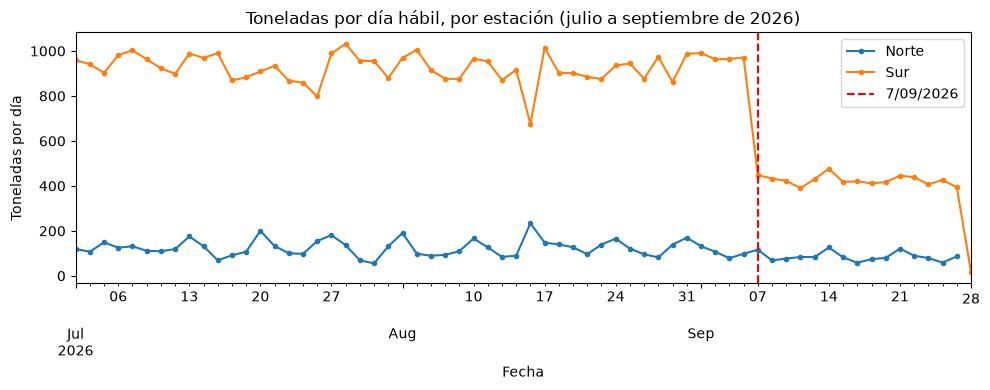

,Agosto a 4/09,Desde 7/09
estacion,,
Norte,125.0,85.0
Sur,923.0,400.0


In [17]:
# Paso 10 bis · Datos recientes incompletos

# Qué hacemos: revisar si los últimos días del dataset están completos.
# Por qué: Seattle sigue actualizando el dataset, y los días más recientes
# pueden estar cargados a medias. Si los usamos para evaluar, mediríamos
# el error de la carga de datos, no el error del modelo.

# Tomamos desde julio de 2026 y sumamos las toneladas de cada estación por día
reciente = df[df["fecha"] >= "2026-07-01"]
diario = reciente.groupby(["fecha", "estacion"])["toneladas"].sum().unstack()

ax = diario.plot(marker=".", figsize=(10, 4))
# Línea vertical en el primer día con datos anómalos
ax.axvline(pd.Timestamp("2026-09-07"), color="red", linestyle="--", label="7/09/2026")
ax.set_title("Toneladas por día hábil, por estación (julio a septiembre de 2026)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Toneladas por día")
ax.legend()
plt.tight_layout()
plt.show()

# Promedio diario antes y después del 7/09
antes = diario.loc["2026-08-01":"2026-09-04"].mean().round(0)
despues = diario.loc["2026-09-07":].mean().round(0)
pd.DataFrame({"Agosto a 4/09": antes, "Desde 7/09": despues})

In [18]:
# Último día con datos completos: viernes 4/09/2026
FECHA_FIN = "2026-09-04"

print("Filas que se eliminan:", (df["fecha"] > FECHA_FIN).sum())
df = df[df["fecha"] <= FECHA_FIN]
print("Filas:", len(df))

Filas que se eliminan: 78
Filas: 12478


**Decisión:** se excluyen los datos posteriores al **4/09/2026**. Desde el lunes 7/09 las dos estaciones registran mucho menos de lo normal, de golpe y en los tres tipos de residuo a la vez: la Sur pasa de unas 923 a 400 t por día y la Norte de 125 a 85, y el 28/09 casi no tiene registros. No hay feriado ni causa operativa que lo explique: lo más probable es que Seattle todavía no haya terminado de cargar esos días, ya que el dataset se sigue actualizando.

Si se incluyeran, la evaluación mediría el error de la carga incompleta y no el del modelo. Se pierden 78 filas, el 3 % del período de prueba.

In [19]:
# Paso 11 · Crear variables de entrada
# 11a · Variables de calendario

# Qué hacemos: sacar de la fecha y del historial información que el modelo pueda usar.

# Por qué: el modelo no entiende “una fecha”, pero sí “es lunes”, “es diciembre” o “es feriado”. Le traducimos la fecha a factores que influyen en la recolección

# Año y mes, obtenidos de la fecha
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month

# Día de la semana con nombre (y no como número), para que las reglas
# del árbol se puedan leer: "si es lunes..." en vez de "si día <= 0.5..."
dias = ["Lunes", "Martes", "Miercoles", "Jueves", "Viernes"]
# enumerate(dias) da los pares (0, "Lunes"), (1, "Martes")...;
# dict los convierte en {0: "Lunes", 1: "Martes", ...} y map reemplaza cada número
df["dia_semana"] = df["fecha"].dt.dayofweek.map(dict(enumerate(dias)))

# Feriados federales de EE. UU. entre la primera y la última fecha que tenemos
feriados = USFederalHolidayCalendar().holidays(df["fecha"].min(), df["fecha"].max())
# isin marca True si la fecha es feriado; astype(int) lo convierte en 1 y 0
df["feriado"] = df["fecha"].isin(feriados).astype(int)

print("Filas marcadas como feriado:", df["feriado"].sum())
df.head()

Filas marcadas como feriado: 429


,fecha,estacion,tipo,toneladas,viajes,anio,mes,dia_semana,feriado
11177,2017-01-02,Norte,Basura,70.523624,23,2017,1,Lunes,1
11178,2017-01-02,Norte,Organicos,23.750000,7,2017,1,Lunes,1
11179,2017-01-02,Sur,Basura,364.491521,111,2017,1,Lunes,1
11180,2017-01-02,Sur,Organicos,233.762208,48,2017,1,Lunes,1
11181,2017-01-02,Sur,Reciclables,402.273225,93,2017,1,Lunes,1


**Por qué el feriado:** algunos feriados caen en día hábil, y ese día la recolección cambia (se suspende o se corre al día siguiente). Sin esta variable, el modelo vería un lunes feriado con poca carga y no tendría forma de explicárselo.

In [20]:
# 11b · Días sin recolección

# Toneladas promedio en días comunes y en feriados, para ver la diferencia
df.groupby("feriado")["toneladas"].mean().round(1)

feriado
0    221.3
1    201.5
Name: toneladas, dtype: float64

In [21]:
# Por qué: la variable feriado mezcla dos situaciones muy distintas. 
# En la mayoría de los feriados federales se recolecta casi normal, pero en tres días prácticamente no hay recolección. 
# El modelo no tiene forma de distinguirlos si solo sabe “es feriado”.

# Variable sin_recoleccion: 1 en los tres días del año sin recolección residencial.
# Se marca la FECHA EXACTA del feriado, no el día trasladado: cuando Navidad o
# Año Nuevo caen en fin de semana, el feriado oficial se pasa a un día hábil,
# pero ese día se recolecta normal.

f = df["fecha"]

# Acción de Gracias: cuarto jueves de noviembre.
# Un jueves (dayofweek == 3) entre el 22 y el 28 siempre es el cuarto del mes
accion_de_gracias = (f.dt.month == 11) & (f.dt.dayofweek == 3) & (f.dt.day >= 22) & (f.dt.day <= 28)

# Navidad y Año Nuevo: fecha fija
navidad = (f.dt.month == 12) & (f.dt.day == 25)
anio_nuevo = (f.dt.month == 1) & (f.dt.day == 1)

# | significa "o": basta con que se cumpla una de las tres
df["sin_recoleccion"] = (accion_de_gracias | navidad | anio_nuevo).astype(int)

print("Días sin recolección:", df.loc[df["sin_recoleccion"] == 1, "fecha"].nunique())

# Comparación: días comunes, feriados con recolección y días sin recolección
df.groupby(["feriado", "sin_recoleccion"])["toneladas"].mean().round(1)

Días sin recolección: 23


feriado  sin_recoleccion
0        0                  221.3
1        0                  228.5
         1                   32.1
Name: toneladas, dtype: float64

**Variable `sin_recoleccion`:** vale 1 en Acción de Gracias, el 25 de diciembre y el 1 de enero, en su fecha exacta. Los feriados federales se comportan de dos formas: en la mayoría se recolecta con normalidad (228,5 t promedio, similar a un día común), pero en estos tres días prácticamente no hay recolección (32,1 t promedio). Con una sola variable `feriado`, el modelo no podía distinguirlos. Se conoce de antemano, por lo que no genera fuga de información.

Se marca la fecha exacta y no el feriado trasladado, porque cuando Navidad o Año Nuevo caen en fin de semana, el día hábil al que se traslada el feriado tiene recolección normal.

**Limitaciones:** en la temporada 2023-24 estos tres días tuvieron recolección parcial (entre 563 y 627 t para toda la ciudad), por lo que el modelo se equivocará en ellos. Además, la semana siguiente a un día sin recolección tiene un valor de "semana anterior" casi nulo que no representa la carga habitual.

In [22]:
# 11c · Valores de la semana anterior

# Por qué: lo que pasó el mismo día de la semana anterior es la mejor pista de lo que va a pasar hoy. 
# Si el lunes pasado la estación Sur recibió 380 toneladas de basura, este lunes probablemente reciba algo parecido. 
# Y como es información del pasado, ya se conoce al momento de predecir.

# Las columnas que identifican cada fila (las mismas del Paso 6)
clave = ["fecha", "estacion", "tipo"]

# 1. Copiamos la clave y los valores que queremos traer de la semana anterior
previo = df[clave + ["toneladas", "viajes"]].copy()

# 2. Le sumamos 7 días a la fecha: así el dato del lunes 2 queda con fecha
#    lunes 9, listo para unirse con la fila del lunes 9
previo["fecha"] = previo["fecha"] + pd.Timedelta(days=7)

# 3. Renombramos para que no choquen con las columnas originales
previo = previo.rename(columns={
    "toneladas": "toneladas_sem_ant",
    "viajes": "viajes_sem_ant",
})

# 4. Unimos: a cada fila le pegamos los valores de su misma estación y tipo, 7 días antes.
#    how="left" conserva todas las filas de df, aunque no encuentren pareja
filas_antes = len(df)
df = df.merge(previo, on=clave, how="left")

# Control: el merge no tiene que agregar filas (si lo hace, había claves repetidas)
print("Filas antes:", filas_antes, "| después:", len(df))
print("Filas sin dato de la semana anterior:", df["toneladas_sem_ant"].isna().sum())

Filas antes: 12478 | después: 12478
Filas sin dato de la semana anterior: 148


**Por qué con `merge` y no con `shift`:** shift(1) toma la fila de arriba, que podría ser de otra estación, otro tipo, o de un día distinto si en el medio hubo un feriado sin registro. Con el merge buscás exactamente la misma estación y el mismo tipo, 7 días antes, sin importar cómo estén ordenadas las filas.

In [23]:
# 11d · Eliminar las filas sin dato previo

# dropna elimina las filas con vacío en esa columna
df = df.dropna(subset=["toneladas_sem_ant"])

# Al haber vacíos, pandas había pasado los viajes a decimal (para poder representar
# el vacío); ahora que no hay, los volvemos a entero
df["viajes_sem_ant"] = df["viajes_sem_ant"].astype(int)

# Ordenamos y renumeramos las filas de 0 en adelante
df = df.sort_values(clave).reset_index(drop=True)
print("Filas finales:", len(df))

Filas finales: 12330


**Por qué eliminarlas y no rellenarlas:** son pocas (cerca del 1 %), y rellenarlas con un promedio inventaría un dato. Además, así los dos modelos usan exactamente las mismas filas.

**Variables creadas en el Paso 11**

| Variable | Descripción |
| --- | --- |
| `anio`, `mes` | Obtenidos de la fecha |
| `dia_semana` | De lunes a viernes |
| `feriado` | 1 si es feriado federal de EE. UU. |
| `sin_recoleccion` | 1 en Acción de Gracias, 25 de diciembre y 1 de enero (fecha exacta) |
| `toneladas_sem_ant` | Toneladas del mismo día de la semana anterior, misma estación y tipo |
| `viajes_sem_ant` | Viajes del mismo día de la semana anterior, misma estación y tipo |

Las variables de la semana anterior usan solo información pasada, por lo que se conocen al momento de predecir. Se eliminaron 148 filas sin dato de la semana anterior (comienzo de 2017 y semanas posteriores a feriados), cerca del 1 % del total.

**Limitación:** se usan los feriados federales de EE. UU., que pueden no coincidir exactamente con el calendario de recolección de Seattle.

## Paso 12 · Regla contra la fuga de información

Ninguna variable de entrada puede depender de la respuesta que se quiere predecir, ni conocerse recién después del momento de la predicción.

- **Regresión** (objetivo: `toneladas`): no se usa `viajes` del mismo día. Tiene una correlación de 0,95 con las toneladas y solo se conoce cuando el día terminó, cuando ya no tiene sentido predecir.
- **Clasificación** (objetivo: `alta_demanda`): no se usan `viajes` ni `toneladas` del mismo día. Los viajes definen la categoría, y usarlos revelaría la respuesta.
- Las variables de la semana anterior (`toneladas_sem_ant`, `viajes_sem_ant`) y `sin_recoleccion` **sí** pueden usarse en los dos modelos, porque se conocen antes del día a predecir.

In [24]:
# Paso 13 · Guardar el dataset limpio

# index=False evita guardar la numeración de filas como una columna extra
df.to_csv("../data/processed/datos_limpios.csv", index=False)

# Verificación: lo volvemos a leer como lo van a leer los notebooks de los modelos, y revisamos que esté bien.
# parse_dates convierte la columna fecha a tipo fecha al leer
control = pd.read_csv("../data/processed/datos_limpios.csv", parse_dates=["fecha"])
print("Filas:", len(control))
print("Vacíos en total:", control.isna().sum().sum())
print("Desde", control["fecha"].min().date(), "hasta", control["fecha"].max().date())
control.dtypes

Filas: 12330
Vacíos en total: 0
Desde 2017-01-09 hasta 2026-09-04


fecha                datetime64[us]
estacion                        str
tipo                            str
toneladas                   float64
viajes                        int64
anio                          int64
mes                           int64
dia_semana                      str
feriado                       int64
sin_recoleccion               int64
toneladas_sem_ant           float64
viajes_sem_ant                int64
dtype: object